# AI Lab – Week 1: Daten, Splits und Metriken

Milestone Week 1 (Kick-off-Folie 15):
1. Daten laden; Essays pro Label, Generator und Prompt zählen
2. Textlängen von Mensch und KI vergleichen
3. Generatoren mit genug Essays wählen; Random-Split und Leave-One-Generator-Out-(LOGO-)Folds definieren
4. Metriken festlegen: ROC-AUC und F1

# Hilsfunktionen und Libs

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import OneHotEncoder

sys.path.append("../src")   # damit Python unsere Module in src/ findet

from data_utils import DATA, RAW_CSV, DATASET_SHA256, GENERATOR, load_raw, load_essays, get_fold
from splits import make_splits, check, summarize, MIN_ESSAYS
from metrics import choose_threshold, evaluate, bootstrap_auc_ci

FIGURES = Path("../docs/slides/week1/figures")   # Abbildungen für die Folien
RESULTS = Path("../results/week1")               # Tabellen

## 1. Rohdaten

Es wird der Community-Datensatz DAIGT v2 genutzt (`thedrcat/daigt-v2-train-dataset`), weil das
Trainingsset der Competition "LLM – Detect AI Generated Text" fast nur menschliche Essays enthält
(1 375 Mensch, 3 KI). 

In [11]:
raw = load_raw()
print(raw.shape)
raw.head(3)

(44868, 5)


,text,label,prompt_name,source,RDizzl3_seven
0,Phones\n\nModern humans today are always on th...,0,Phones and driving,persuade_corpus,False
1,This essay will explain if drivers should or s...,0,Phones and driving,persuade_corpus,False
2,Driving while the use of cellular devices\n\nT...,0,Phones and driving,persuade_corpus,False


In [12]:
print(raw["label"].value_counts().rename({0: "human", 1: "AI"}))
raw.groupby(["source", "label"]).size().sort_values(ascending=False).to_frame("essays")

label
human    27371
AI       17497
Name: count, dtype: int64


,,essays
source,label,
persuade_corpus,0,25996
chat_gpt_moth,1,2421
mistral7binstruct_v2,1,2421
mistral7binstruct_v1,1,2421
llama2_chat,1,2421
kingki19_palm,1,1384
train_essays,0,1375
llama_70b_v1,1,1172
falcon_180b_v1,1,1055


Die 17 Quellen werden zu Generator-Familien zusammengefasst.

In [13]:
pd.Series(GENERATOR, name="Familie").rename_axis("source").to_frame()

,Familie
source,
chat_gpt_moth,gpt
radek_500,gpt
radekgpt4,gpt
llama2_chat,llama2
llama_70b_v1,llama2
NousResearch/Llama-2-7b-chat-hf,llama2
mistral7binstruct_v1,mistral
mistral7binstruct_v2,mistral
mistralai/Mistral-7B-Instruct-v0.1,mistral


## 2. Datenqualität: Artefakte und Duplikate

In [6]:
# 1. Generator-Familie zu jedem Roh-Essay hinzufügen
raw_check = raw.copy()
raw_check["generator"] = raw_check["source"].map(GENERATOR)
raw_check.loc[raw_check["label"] == 0, "generator"] = "human"

# 2. Für jeden Essay prüfen, ob ein Artefakt vorkommt (True / False)
text = raw_check["text"]
raw_check["beginnt_mit_leerzeichen"] = text.str.startswith((" ", "\n", "\t"))
raw_check["platzhalter_name"] = text.str.contains("[Your Name]", regex=False) | text.str.contains("[Name]", regex=False)
raw_check["zeile_title"] = text.str.contains("Title:", regex=False)
raw_check["sonderzeichen"] = ~text.map(str.isascii)   # z. B. typografische Anführungszeichen

# 3. Anteil pro Generator in Prozent (Mittelwert von True/False = Anteil)
artefakte = ["beginnt_mit_leerzeichen", "platzhalter_name", "zeile_title", "sonderzeichen"]
anteil = raw_check.groupby("generator")[artefakte].mean() * 100
anteil.round(1)

,beginnt_mit_leerzeichen,platzhalter_name,zeile_title,sonderzeichen
generator,,,,
claude,11.0,0.2,0.0,6.8
cohere,99.7,9.7,0.0,8.9
falcon,0.0,7.6,1.0,6.6
gpt,0.0,11.2,3.1,28.8
human,0.0,0.0,0.0,30.3
llama2,10.0,3.8,4.0,17.5
mistral,53.8,4.2,0.5,1.0
palm,0.0,33.2,0.5,3.1


99.7 % der Cohere- und 54 % der Mistral-Rohtexte beginnen mit einem Leerzeichen,
bei Menschen 0 %. Das ist ein reines Formatierungs-Artefakt. Daher normalisiert `normalize_text()` den Whitespace.
Tippfehler, Groß-/Kleinschreibung und doppelte Leerzeichen bleiben erhalten, weil sie echte Schreibmerkmale sind.

### Near-Duplicates

In [7]:
dups = pd.read_csv(DATA / "near_duplicates.csv")
print(len(dups), "Paare mit Kosinus > 0.9")
dups.groupby(["src_a", "src_b"]).size().sort_values(ascending=False).to_frame("Paare")

1322 Paare mit Kosinus > 0.9


Paare
src_a           src_b                      
persuade_corpus train_essays           1291
                persuade_corpus          29
                mistral7binstruct_v2      2

Fast alle Kaggle-`train_essays` sind Kopien von Persuade-Essays. Ohne Dedup würde derselbe
menschliche Essay in Train und Test landen und alle Scores aufblähen. Pro Duplikat-Gruppe bleibt
ein Essay (bevorzugt die Persuade-Version). Gruppen mit widersprüchlichen Labels werden ganz verworfen.

In [8]:
df = load_essays(verbose=True)
print(df.shape)
df.head(3)

Bereinigung: {'raw': 44868, 'unknown_generator': 3, 'ai_below_min_words': 5, 'exact_duplicates': 4, 'near_duplicates': 1311, 'final': 43545}
(43545, 9)


,essay_id,text,text_raw,label,generator,source,prompt_name,n_words,n_chars
0,6a3c9cf0be9ff73e,Phones\n\nModern humans today are always on th...,Phones\n\nModern humans today are always on th...,0,human,persuade_corpus,Phones and driving,379,2025
1,ee7f1eda93845b6a,This essay will explain if drivers should or s...,This essay will explain if drivers should or s...,0,human,persuade_corpus,Phones and driving,366,2071
2,1a211f4c2ad3bb52,Driving while the use of cellular devices\n\nT...,Driving while the use of cellular devices\n\nT...,0,human,persuade_corpus,Phones and driving,178,1041


## 3. Zählungen pro Label, Generator und Prompt

In [9]:
counts = df.groupby("generator").agg(essays=("essay_id", "size"),
                                     prompts=("prompt_name", "nunique")) \
           .sort_values("essays", ascending=False)
counts.to_csv(RESULTS / "per_generator.csv")
counts

,essays,prompts
generator,,
human,26058,15
mistral,5236,15
llama2,3992,15
gpt,3121,14
claude,2000,15
palm,1733,8
falcon,1055,15
cohere,350,8


In [10]:
selected = sorted(counts.drop("human").query("essays >= @MIN_ESSAYS").index)
print(f"Generatoren mit >= {MIN_ESSAYS} Essays (eigener LOGO-Fold):", selected)

Generatoren mit >= 1000 Essays (eigener LOGO-Fold): ['claude', 'falcon', 'gpt', 'llama2', 'mistral', 'palm']


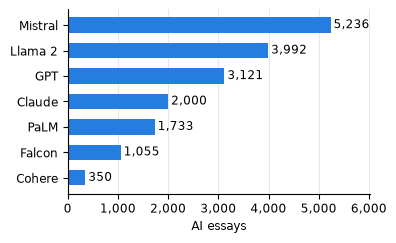

In [11]:
ai_counts = df[df["label"] == 1]["generator"].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(3.9, 2.4))
ax.barh([NAMES[g] for g in ai_counts.index], ai_counts.values, color=BLUE, height=0.6)
for y, value in enumerate(ai_counts.values):
    ax.text(value + 60, y, f"{value:,}", va="center")     # Zahl rechts neben dem Balken
ax.set_xlim(0, ai_counts.max() * 1.15)
ax.set_xlabel("AI essays")
ax.xaxis.set_major_formatter("{x:,.0f}")
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)

fig.savefig(FIGURES / "counts_per_generator.pdf", bbox_inches="tight", transparent=True)
plt.show()

Cohere hat nur 350 Essays. Ein eigener Testfold wäre zu klein für eine stabile AUC, deshalb
bleibt Cohere ausschließlich im Training.

### Prompts

Die 15 Prompts (Essay-Themen) sind nicht gleich über die Generatoren verteilt.

In [12]:
prompt_table = pd.crosstab(df["prompt_name"], df["generator"], margins=True)
prompt_table.to_csv(RESULTS / "prompt_by_generator.csv")
prompt_table

generator,claude,cohere,falcon,gpt,human,llama2,mistral,palm,All
prompt_name,,,,,,,,,
"""A Cowboy Who Rode the Waves""",141,50,46,47,1372,120,70,50,1896
Car-free cities,97,49,156,362,1982,398,225,761,4030
Cell phones at school,132,0,41,49,1656,123,118,0,2119
Community service,118,0,30,64,1542,149,189,0,2092
Distance learning,121,0,219,830,2155,732,1492,0,5549
Does the electoral college work?,130,50,25,353,2104,233,205,721,3821
Driverless cars,155,50,27,11,1886,61,10,50,2250
Exploring Venus,138,50,33,4,1862,33,6,50,2176
Facial action coding system,148,50,101,82,2167,293,193,50,3084


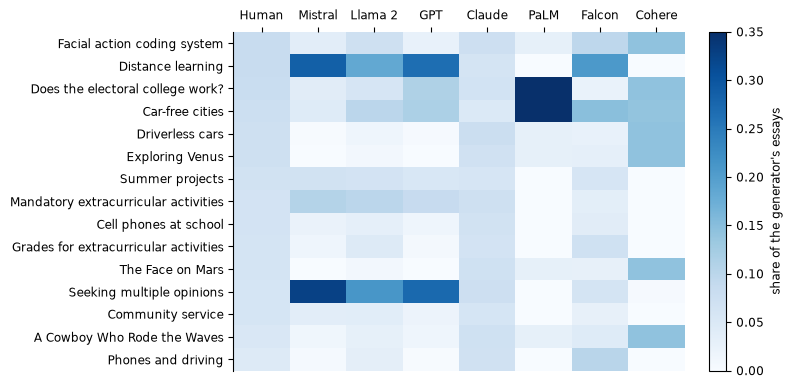

In [13]:
order = ["human"] + list(ai_counts.sort_values(ascending=False).index)
table = pd.crosstab(df["prompt_name"].str.strip('"'), df["generator"])[order]
share = table / table.sum()                     # Anteil der Essays eines Generators pro Prompt
share = share.sort_values("human", ascending=False)

fig, ax = plt.subplots(figsize=(6.4, 4.4))
image = ax.imshow(share.values, cmap="Blues", vmin=0, vmax=0.35, aspect="auto")
ax.set_xticks(range(len(order)), [NAMES[g] for g in order])
ax.set_yticks(range(len(share)), share.index)
ax.xaxis.tick_top()
ax.spines["bottom"].set_visible(False)
fig.colorbar(image, ax=ax, fraction=0.04, label="share of the generator's essays")

fig.savefig(FIGURES / "prompt_by_generator.pdf", bbox_inches="tight", transparent=True)
plt.show()

In [14]:
human_share = pd.crosstab(df["prompt_name"], df["label"], normalize="index")[0].sort_values()
human_share.rename("Anteil human").round(3).to_frame()

,Anteil human
prompt_name,
Seeking multiple opinions,0.300
Distance learning,0.388
Car-free cities,0.492
Mandatory extracurricular activities,0.543
Does the electoral college work?,0.551
Summer projects,0.648
Facial action coding system,0.703
"""A Cowboy Who Rode the Waves""",0.724
Phones and driving,0.735


Der Anteil menschlicher Essays schwankt je Prompt zwischen 30 % und 86 %. GPT, Mistral und
Llama 2 konzentrieren sich auf Distance learning und Seeking multiple opinions.
Ein Detektor kann also teilweise das Thema statt des Schreibstils lernen. Das prüfen wir unten.

## 4. Textlängen: Mensch vs. KI

In [15]:
length_stats = df.groupby("generator")["n_words"].describe(percentiles=[.05, .25, .5, .75, .95]).round(0)
length_stats = length_stats.sort_values("50%", ascending=False)
length_stats.to_csv(RESULTS / "length_per_generator.csv")
length_stats

,count,mean,std,min,5%,25%,50%,75%,95%,max
generator,,,,,,,,,,
palm,1733.0,393.0,86.0,170.0,264.0,335.0,385.0,443.0,547.0,746.0
human,26058.0,411.0,188.0,143.0,181.0,269.0,374.0,509.0,783.0,1656.0
mistral,5236.0,349.0,67.0,84.0,232.0,300.0,358.0,402.0,437.0,525.0
llama2,3992.0,340.0,63.0,77.0,256.0,297.0,335.0,372.0,451.0,818.0
cohere,350.0,330.0,108.0,129.0,198.0,250.0,308.0,380.0,539.0,713.0
claude,2000.0,310.0,42.0,160.0,247.0,281.0,308.0,336.0,382.0,507.0
falcon,1055.0,295.0,61.0,50.0,201.0,252.0,295.0,335.0,402.0,441.0
gpt,3121.0,272.0,149.0,61.0,113.0,167.0,225.0,322.0,599.0,785.0


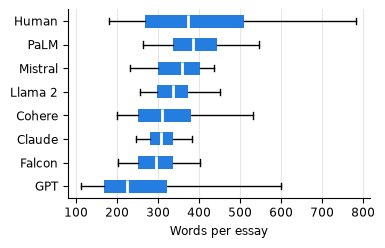

In [16]:
# Reihenfolge: Human oben, dann KI-Generatoren nach Median-Länge
ai_medians = df[df["label"] == 1].groupby("generator")["n_words"].median()
order = ["human"] + list(ai_medians.sort_values(ascending=False).index)
lengths = [df.loc[df["generator"] == g, "n_words"] for g in order]

fig, ax = plt.subplots(figsize=(3.9, 2.45))
ax.boxplot(lengths, orientation="horizontal", tick_labels=[NAMES[g] for g in order],
           whis=(5, 95),                # Whisker = 5. bis 95. Perzentil
           showfliers=False, widths=0.55, patch_artist=True,
           boxprops={"facecolor": BLUE, "edgecolor": "none"},
           medianprops={"color": "white", "linewidth": 2})
ax.invert_yaxis()                       # Human oben
ax.set_xlabel("Words per essay")
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)

fig.savefig(FIGURES / "length_per_generator.pdf", bbox_inches="tight", transparent=True)
plt.show()

In [17]:
h_min = df.loc[df.label == 0, "n_words"].min()
print("Kürzester menschlicher Essay:", h_min, "Wörter")
print("KI-Essays kürzer als jeder menschliche:", ((df.label == 1) & (df.n_words < h_min)).sum())

Kürzester menschlicher Essay: 143 Wörter
KI-Essays kürzer als jeder menschliche: 525


**Befund:** Menschen schreiben im Median 374 Wörter, KI 328. Die Streuung der KI-Essays ist viel enger,
und GPT schreibt deutlich kürzer als alle anderen. Die Länge ist also ein naheliegender Shortcut.

## 5. Splits

**Random-Split:** 70 / 10 / 20 % (train / val / test), stratifiziert nach Generator (inkl. human), Seed 42.

**LOGO-Fold für Generator *g*:**
- train / val = Random-train / -val **ohne alle Essays von *g***
- test = Random-test, eingeschränkt auf {human, *g*}

So werten Random-Split und LOGO-Fold *g* auf **exakt denselben Testzeilen** aus. Der einzige
Unterschied ist, ob *g* im Training vorkam. Die Differenz
AUC<sub>random</sub>(*g*) − AUC<sub>LOGO</sub>(*g*) ist damit direkt der Generalisierungsverlust.

In [18]:
splits, selected = make_splits(df)
check(splits, selected)          # wirft AssertionError bei Leakage oder abweichenden Testzeilen
split_cols = ["random"] + [f"logo_{g}" for g in selected]

summary = summarize(splits, split_cols)
summary.pivot(index="split", columns="part", values=["human", "ai"])

human                 ai             
part          test  train   val  test  train   val
split                                             
logo_claude   5212  18240  2606   400  10841  1549
logo_falcon   5212  18240  2606   211  11503  1643
logo_gpt      5212  18240  2606   624  10056  1437
logo_llama2   5212  18240  2606   798   9446  1350
logo_mistral  5212  18240  2606  1047   8576  1225
logo_palm     5212  18240  2606   347  11028  1576
random        5212  18240  2606  3497  12241  1749

Reproduzierbarkeit: Die neu erzeugten Splits müssen mit der committeten `src/data/splits.csv` übereinstimmen.

In [19]:
saved = pd.read_csv(DATA / "splits.csv").set_index("essay_id")[split_cols]
now = splits.set_index("essay_id")[split_cols].loc[saved.index]
print("identisch mit splits.csv:", now.equals(saved))

identisch mit splits.csv: True


## 6. Shortcut-Checks: Wie weit kommt man mit einem einzigen Merkmal?

Für jeden Split trainieren wir auf `train` einen Klassifikator, der **nur ein Merkmal** sieht,
und messen die ROC-AUC auf `test`:
- **Länge:** Wortanzahl (kleiner Gradient-Boosting-Baum, auch nicht-monotone Zusammenhänge)
- **Prompt:** One-Hot-Thema + logistische Regression
- **Leerzeichen am Anfang:** auf dem Roh- bzw. normalisierten Text

Diese Werte sind die Referenzlinien, die jedes echte Modell klar übertreffen muss.

In [20]:
def auc_length_only(train, test):
    # Klassifikator, der nur die Wortanzahl sieht.
    model = HistGradientBoostingClassifier(max_depth=3, random_state=0)
    model.fit(train[["n_words"]], train["label"])
    return roc_auc_score(test["label"], model.predict_proba(test[["n_words"]])[:, 1])


def auc_prompt_only(train, test):
    # Klassifikator, der nur das Thema (Prompt) sieht.
    encoder = OneHotEncoder(handle_unknown="ignore").fit(train[["prompt_name"]])
    model = LogisticRegression(max_iter=1000)
    model.fit(encoder.transform(train[["prompt_name"]]), train["label"])
    scores = model.predict_proba(encoder.transform(test[["prompt_name"]]))[:, 1]
    return roc_auc_score(test["label"], scores)


def auc_leading_space(test, text_column):
    # Ohne Training: Vorhersage "KI", wenn der Text mit einem Leerzeichen beginnt.
    starts_with_space = test[text_column].str.startswith((" ", "\n", "\t"))
    return roc_auc_score(test["label"], starts_with_space)


rows = []
for split in split_cols:
    train = splits[splits[split] == "train"]
    test = splits[splits[split] == "test"]
    rows.append({
        "split": split,
        "length": auc_length_only(train, test),
        "prompt": auc_prompt_only(train, test),
        "leading space (raw)": auc_leading_space(test, "text_raw"),
        "leading space (cleaned)": auc_leading_space(test, "text"),
    })

shortcuts = pd.DataFrame(rows).set_index("split").round(3)
shortcuts.to_csv(RESULTS / "shortcut_auc.csv")
shortcuts

,length,prompt,leading space (raw),leading space (cleaned)
split,,,,
random,0.716,0.715,0.608,0.5
logo_claude,0.752,0.492,0.566,0.5
logo_falcon,0.711,0.598,0.500,0.5
logo_gpt,0.438,0.801,0.500,0.5
logo_llama2,0.747,0.714,0.553,0.5
logo_mistral,0.712,0.776,0.761,0.5
logo_palm,0.628,0.610,0.500,0.5


**Befund:**
- Länge allein erreicht **0.72** auf dem Random-Split, Prompt allein ebenfalls **0.72**.
- Bei zurückgehaltenem GPT kippt die Längenregel auf **0.44** (schlechter als Zufall), weil GPT kürzer
  schreibt als die Trainings-Generatoren. Das Thema erreicht dagegen **0.80**.
- Nach der Normalisierung ist der Leerzeichen-Shortcut weg (AUC 0.5).

## 7. Metriken

| Metrik | Rolle | Begründung |
|---|---|---|
| **ROC-AUC** | primär | schwellenwertfrei; unabhängig vom Klassenverhältnis, das je LOGO-Fold stark variiert; Competition-Metrik; dazu 95 %-Bootstrap-Konfidenzintervall |
| **F1** (Klasse KI) | sekundär | Schwelle wird auf `val` gewählt (max. F1), nie auf `test`. Im LOGO-Fold enthält `val` den Generator *g* nicht, die Schwelle ist also realistisch „blind“ |
| **TPR @ 1 % FPR** | zusätzlich | Anteil erkannter KI-Essays, wenn höchstens 1 von 100 Studierenden fälschlich beschuldigt wird, denn das ist der teure Fehler |

Kurze Demonstration mit der Längen-Shortcut-Regel auf dem Random-Split:

In [21]:
from sklearn.ensemble import HistGradientBoostingClassifier

tr, va, te = get_fold(splits, "random")
clf = HistGradientBoostingClassifier(max_depth=3, random_state=0).fit(tr[["n_words"]], tr.label)
s_val, s_test = clf.predict_proba(va[["n_words"]])[:, 1], clf.predict_proba(te[["n_words"]])[:, 1]

thr = choose_threshold(va.label, s_val)
res = evaluate(te.label, s_test, thr)
res["auc_95ci"] = tuple(round(x, 3) for x in bootstrap_auc_ci(te.label, s_test, n_boot=500))
pd.Series(res)

roc_auc            0.715899
f1                 0.646904
tpr@1%fpr          0.042894
threshold          0.307747
n                      8709
n_ai                   3497
auc_95ci     (0.706, 0.725)
dtype: object

## 8. Zusammenfassung und nächste Schritte

**Erledigt (Milestone Week 1):**
- Daten geladen und bereinigt: 44 868 → **43 545 Essays** (26 058 human, 17 487 KI, 7 Familien, 15 Prompts)
- Leakage durch 1 311 Near-Duplicates entfernt, Whitespace-Artefakt neutralisiert
- 6 LOGO-Folds (Claude, Falcon, GPT, Llama 2, Mistral, PaLM) und Random-Split mit gepaartem Testdesign
- Metriken festgelegt: ROC-AUC (primär), F1 mit Val-Schwelle, TPR @ 1 % FPR

**Week 2 (Check-in 04.12.):**
- TF-IDF auf Zeichen-3–5-Grammen + logistische Regression, Vectorizer nur auf `train` fitten
- Auswertung auf dem Random-Split und allen 6 LOGO-Folds, mit Länge und Prompt als Referenzlinien
- GPU-Umgebung (DACHS / Colab) für DeBERTa-v3-small vorbereiten

**Offene Fragen:**
1. LOGO nach Modell-*Familie* oder nach einzelner Modellversion?
2. Thema und Label sind vermischt. Reicht die Prompt-Referenz, oder brauchen wir ein prompt-balanciertes Testset?
3. LOGO-Folds haben bis zu 30 % weniger KI-Trainingsessays. Brauchen wir eine größengleiche Kontrolle?